In [1]:
import pandas as pd


def build_labeled_expectosc(brca_path, vep_path, expectosc_path, verbose=True):
    """
    Attach the `Class` label from the BRCA/PALB2 variant table to each row of the
    Seqweaver/expectosc table, using VEP output to bridge HGVSc (transcript
    coordinates) -> genomic coordinates (chrom_pos_ref_alt).

    Returns the expectosc table (same row count/order) with Class, Gene,
    Transcript, HGVSc, HGVSp appended (NaN where no match found).
    """
    # ---------- 1. brca ----------
    brca = pd.read_csv(brca_path)
    brca = brca.loc[:, [c for c in brca.columns if not c.startswith("Unnamed")]]
    brca["variant_key"] = brca["Transcript"].astype(str) + ":" + brca["HGVSc"].astype(str)

    # ---------- 2. VEP output ----------
    with open(vep_path) as f:
        lines = f.readlines()
    header_idx = next(i for i, l in enumerate(lines) if l.startswith("#Uploaded_variation"))
    vep = pd.read_csv(vep_path, sep="\t", skiprows=header_idx)
    vep = vep.rename(columns={"#Uploaded_variation": "Uploaded_variation"})

    vep = vep[vep["Feature_type"] == "Transcript"].copy()
    vep = vep.merge(
        brca[["variant_key", "Transcript"]].drop_duplicates(),
        left_on=["Uploaded_variation", "Feature"],
        right_on=["variant_key", "Transcript"],
        how="inner",
    ).drop(columns=["Transcript", "Gene"])
    vep = vep.rename(columns={"Feature": "VEP_Feature_transcript"})

    # ---------- 3. genomic location ----------
    loc_split = vep["Location"].str.split(":", expand=True)
    vep["chrom"] = loc_split[0].str.replace("chr", "", regex=False)
    pos_part = loc_split[1].str.split("-", expand=True)
    vep["pos_1based"] = pd.to_numeric(pos_part[0], errors="coerce")
    vep["ref"] = vep["GIVEN_REF"]
    vep["alt"] = vep["Allele"]

    vep_snv = vep[
        vep["pos_1based"].notna()
        & vep["ref"].notna() & vep["alt"].notna()
        & (vep["ref"] != "-") & (vep["alt"] != "-")
    ].copy()

    vep_snv["SNP_0based"] = (
        vep_snv["chrom"].astype(str) + "_" + (vep_snv["pos_1based"].astype(int) - 1).astype(str)
        + "_" + vep_snv["ref"] + "_" + vep_snv["alt"]
    )
    vep_snv["SNP_1based"] = (
        vep_snv["chrom"].astype(str) + "_" + vep_snv["pos_1based"].astype(int).astype(str)
        + "_" + vep_snv["ref"] + "_" + vep_snv["alt"]
    )

    # ---------- 4. expectosc ----------
    expectosc = pd.read_csv(expectosc_path)
    expectosc["chrom"] = expectosc["chrom"].astype(str)

    # ---------- 5. pick coordinate offset that actually matches ----------
    n0 = vep_snv["SNP_0based"].isin(expectosc["SNP"]).sum()
    n1 = vep_snv["SNP_1based"].isin(expectosc["SNP"]).sum()
    key_col = "SNP_0based" if n0 >= n1 else "SNP_1based"

    if verbose:
        print(f"VEP SNV rows available for matching: {len(vep_snv)}")
        print(f"Matches using 0-based (chromStart) key: {n0}")
        print(f"Matches using 1-based key:              {n1}")
        print(f"-> Using '{key_col}' to join.")
        if max(n0, n1) == 0:
            print(
                "WARNING: zero matches on either offset. This usually means a genome-build "
                "mismatch (VEP GRCh38 vs expectosc GRCh37/hg19, or vice versa). Check the "
                "VEP header '## assembly version' line against your expectosc build."
            )
        print()

    # ---------- 6. bring Class onto the VEP rows ----------
    vep_snv = vep_snv.merge(
        brca[["variant_key", "Gene", "Transcript", "HGVSc", "HGVSp", "Class"]],
        on="variant_key", how="left",
    )
    vep_snv = vep_snv.drop_duplicates(subset=[key_col])

    # ---------- 7. left-merge onto expectosc, preserving its row count/order ----------
    result = expectosc.merge(
        vep_snv[[key_col, "Gene", "Transcript", "HGVSc", "HGVSp", "Class"]],
        left_on="SNP", right_on=key_col, how="left",
    ).drop(columns=[key_col])

    assert len(result) == len(expectosc), "Row count changed during merge!"

    if verbose:
        matched = result["Class"].notna().sum()
        print(f"expectosc rows: {len(result)} | rows with a Class assigned: {matched}")

    return result


# ---- usage ----
df = build_labeled_expectosc(
    brca_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/BRCA1_BRCA2_PALB2_varianter_2025_02_10.csv",
    vep_path="/storage/mathelierarea/processed/eirikhoy/action_var/results/vep_output.txt",
    expectosc_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv",
)
df

VEP SNV rows available for matching: 717
Matches using 0-based (chromStart) key: 0
Matches using 1-based key:              0
-> Using 'SNP_0based' to join.

expectosc rows: 10121 | rows with a Class assigned: 0


,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist,Gene,Transcript,HGVSc,HGVSp,Class
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411,NaN,NaN,NaN,NaN,NaN
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415,NaN,NaN,NaN,NaN,NaN
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425,NaN,NaN,NaN,NaN,NaN
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430,NaN,NaN,NaN,NaN,NaN
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10116,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72,NaN,NaN,NaN,NaN,NaN
10117,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66,NaN,NaN,NaN,NaN,NaN
10118,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61,NaN,NaN,NaN,NaN,NaN
10119,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56,NaN,NaN,NaN,NaN,NaN


In [2]:
# ---- usage ----
df = build_labeled_expectosc(
    brca_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/BRCA1_BRCA2_PALB2_varianter_2025_02_10.csv",
    vep_path="/storage/mathelierarea/processed/eirikhoy/action_var/results/vep_grch37_output.txt",
    expectosc_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv",
)
df

VEP SNV rows available for matching: 717
Matches using 0-based (chromStart) key: 17
Matches using 1-based key:              47
-> Using 'SNP_1based' to join.

expectosc rows: 10121 | rows with a Class assigned: 47


,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist,Gene,Transcript,HGVSc,HGVSp,Class
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411,NaN,NaN,NaN,NaN,NaN
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415,NaN,NaN,NaN,NaN,NaN
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425,NaN,NaN,NaN,NaN,NaN
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430,NaN,NaN,NaN,NaN,NaN
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10116,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72,NaN,NaN,NaN,NaN,NaN
10117,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66,NaN,NaN,NaN,NaN,NaN
10118,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61,NaN,NaN,NaN,NaN,NaN
10119,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56,NaN,NaN,NaN,NaN,NaN


In [3]:
df.dropna()

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist,Gene,Transcript,HGVSc,HGVSp,Class
2174,13,32890631,32890632,13_32890631_T_G,T,G,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,1002,BRCA2,NM_000059.4,c.34T>G,p.Phe12Val,3
2175,13,32890637,32890638,13_32890637_A_G,A,G,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,1008,BRCA2,NM_000059.4,c.40A>G,p.Ile14Val,3
2210,13,32893262,32893263,13_32893262_C_T,C,T,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3633,BRCA2,NM_000059.4,c.116C>T,p.Ala39Val,2
2212,13,32893271,32893272,13_32893271_A_G,A,G,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3642,BRCA2,NM_000059.4,c.125A>G,p.Tyr42Cys,1
2215,13,32893291,32893292,13_32893291_G_T,G,T,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3662,BRCA2,NM_000059.4,c.145G>T,p.Glu49Ter,5
2225,13,32893344,32893345,13_32893344_A_G,A,G,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3715,BRCA2,NM_000059.4,c.198A>G,p.Gln66=,1
2231,13,32893369,32893370,13_32893369_G_C,G,C,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3740,BRCA2,NM_000059.4,c.223G>C,p.Ala75Pro,1
2237,13,32893381,32893382,13_32893381_A_G,A,G,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3752,BRCA2,NM_000059.4,c.235A>G,p.Ile79Val,2
2239,13,32893387,32893388,13_32893387_T_A,T,A,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3758,BRCA2,NM_000059.4,c.241T>A,p.Phe81Ile,2
2246,13,32893426,32893427,13_32893426_C_T,C,T,13,32889629,32889630,+,BRCA2,ENSG00000139618,True,3797,BRCA2,NM_000059.4,c.280C>T,p.Pro94Ser,2


In [4]:
import pandas as pd


def build_labeled_expectosc(brca_path, vep_path, expectosc_path, breast_zscore_path=None, verbose=True):
    """
    Attach the `Class` label from the BRCA/PALB2 variant table to each row of the
    Seqweaver/expectosc table, using VEP output to bridge HGVSc (transcript
    coordinates) -> genomic coordinates (chrom_pos_ref_alt), which is how variants
    are identified in the Seqweaver/expectosc table. Optionally also attaches
    per-cell-type ExPecto-SC z-scores (e.g. the breast atlas file) by SNP.

    Parameters
    ----------
    brca_path : str
        Path to the BRCA1/BRCA2/PALB2 variant CSV (columns: Gene, Transcript,
        HGVSc, HGVSp, Class).
    vep_path : str
        Path to the VEP output (tab format), run on the SAME genome build as
        expectosc_path's coordinates (e.g. GRCh37).
    expectosc_path : str
        Path to the Seqweaver/expectosc CSV (columns include chrom, snp_chromStart,
        snp_chromEnd, SNP, ref, alt, gene_name, ...).
    breast_zscore_path : str, optional
        Path to the per-cell-type z-score CSV (columns: SNP, <cell_type_1>, ...,
        <cell_type_N>). Merged in by SNP if provided.
    verbose : bool
        Print diagnostics about match rates and which coordinate offset was used.

    Returns
    -------
    pd.DataFrame
        The expectosc table (same number of rows / order as the input file) with
        Class, Gene, Transcript, HGVSc, HGVSp appended, plus all z-score columns
        from breast_zscore_path if given (NaN where no match was found).
    """

    # ---------- 1. Load brca ----------
    brca = pd.read_csv(brca_path)
    brca = brca.loc[:, [c for c in brca.columns if not c.startswith("Unnamed")]]
    brca["variant_key"] = brca["Transcript"].astype(str) + ":" + brca["HGVSc"].astype(str)

    # ---------- 2. Load VEP output ----------
    with open(vep_path) as f:
        lines = f.readlines()
    header_idx = next(i for i, l in enumerate(lines) if l.startswith("#Uploaded_variation"))
    vep = pd.read_csv(vep_path, sep="\t", skiprows=header_idx)
    vep = vep.rename(columns={"#Uploaded_variation": "Uploaded_variation"})

    # Keep only transcript-level annotations, and only the row matching each
    # variant's *own* transcript (VEP reports every overlapping transcript/gene).
    vep = vep[vep["Feature_type"] == "Transcript"].copy()
    vep = vep.merge(
        brca[["variant_key", "Transcript"]].drop_duplicates(),
        left_on=["Uploaded_variation", "Feature"],
        right_on=["variant_key", "Transcript"],
        how="inner",
    ).drop(columns=["Transcript", "Gene"])  # avoid name collisions with brca's Transcript/Gene columns later
    vep = vep.rename(columns={"Feature": "VEP_Feature_transcript"})

    # ---------- 3. Parse genomic location ----------
    loc_split = vep["Location"].str.split(":", expand=True)
    vep["chrom"] = loc_split[0].str.replace("chr", "", regex=False)
    pos_part = loc_split[1].str.split("-", expand=True)
    vep["pos_1based"] = pd.to_numeric(pos_part[0], errors="coerce")
    vep["ref"] = vep["GIVEN_REF"]
    vep["alt"] = vep["Allele"]

    vep_snv = vep[
        vep["pos_1based"].notna()
        & vep["ref"].notna() & vep["alt"].notna()
        & (vep["ref"] != "-") & (vep["alt"] != "-")
    ].copy()

    vep_snv["SNP_0based"] = (
        vep_snv["chrom"].astype(str) + "_" + (vep_snv["pos_1based"].astype(int) - 1).astype(str)
        + "_" + vep_snv["ref"] + "_" + vep_snv["alt"]
    )
    vep_snv["SNP_1based"] = (
        vep_snv["chrom"].astype(str) + "_" + vep_snv["pos_1based"].astype(int).astype(str)
        + "_" + vep_snv["ref"] + "_" + vep_snv["alt"]
    )

    # ---------- 4. Load expectosc ----------
    expectosc = pd.read_csv(expectosc_path)
    expectosc["chrom"] = expectosc["chrom"].astype(str)

    # ---------- 5. Pick coordinate offset that actually matches ----------
    n0 = vep_snv["SNP_0based"].isin(expectosc["SNP"]).sum()
    n1 = vep_snv["SNP_1based"].isin(expectosc["SNP"]).sum()
    key_col = "SNP_0based" if n0 >= n1 else "SNP_1based"

    if verbose:
        print(f"VEP SNV rows available for matching: {len(vep_snv)}")
        print(f"Matches using 0-based (chromStart) key: {n0}")
        print(f"Matches using 1-based key:              {n1}")
        print(f"-> Using '{key_col}' to join.")
        if max(n0, n1) == 0:
            print(
                "WARNING: zero matches on either offset. This usually means a genome-build "
                "mismatch (VEP vs expectosc). Check the VEP header '## assembly version' line."
            )
        print()

    # ---------- 6. Bring Class onto the VEP rows ----------
    vep_snv = vep_snv.merge(
        brca[["variant_key", "Gene", "Transcript", "HGVSc", "HGVSp", "Class"]],
        on="variant_key", how="left",
    )
    vep_snv = vep_snv.drop_duplicates(subset=[key_col])

    # ---------- 7. Left-merge onto expectosc, preserving its row count/order ----------
    result = expectosc.merge(
        vep_snv[[key_col, "Gene", "Transcript", "HGVSc", "HGVSp", "Class"]],
        left_on="SNP", right_on=key_col, how="left",
    ).drop(columns=[key_col])

    assert len(result) == len(expectosc), "Row count changed during merge!"

    if verbose:
        matched = result["Class"].notna().sum()
        print(f"expectosc rows: {len(result)} | rows with a Class assigned: {matched}")

    # ---------- 8. Optionally attach per-cell-type z-scores, by SNP ----------
    if breast_zscore_path is not None:
        zscores = pd.read_csv(breast_zscore_path)
        zscore_cols = [c for c in zscores.columns if c != "SNP"]

        clashes = set(zscore_cols) & set(result.columns)
        if clashes:
            zscores = zscores.rename(columns={c: f"{c}_zscore" for c in clashes})
            zscore_cols = [f"{c}_zscore" if c in clashes else c for c in zscore_cols]

        result = result.merge(zscores, on="SNP", how="left")
        assert len(result) == len(expectosc), "Row count changed during z-score merge!"

        if verbose:
            z_matched = result[zscore_cols[0]].notna().sum() if zscore_cols else 0
            print(f"z-score columns attached: {len(zscore_cols)} | rows with z-scores: {z_matched}")

    return result


# ---- usage ----
df = build_labeled_expectosc(
    brca_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/BRCA1_BRCA2_PALB2_varianter_2025_02_10.csv",
    vep_path="/storage/mathelierarea/processed/eirikhoy/action_var/results/vep_grch37_output.txt",
    expectosc_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv",
    breast_zscore_path="/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv",
)
df.head()

VEP SNV rows available for matching: 717
Matches using 0-based (chromStart) key: 17
Matches using 1-based key:              47
-> Using 'SNP_1based' to join.

expectosc rows: 10121 | rows with a Class assigned: 47
z-score columns attached: 59 | rows with z-scores: 10121


,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,...,-0.058157,-0.086031,-0.202274,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,...,0.069310,-0.019523,0.158286,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,...,-0.162856,-0.321782,-0.525595,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,...,0.009364,0.034013,0.037675,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,...,0.066755,0.052820,0.095924,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094


In [5]:
df_brca = df.dropna()
df_brca

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
2174,13,32890631,32890632,13_32890631_T_G,T,G,13,32889629,32889630,+,...,0.305014,0.389513,0.398132,0.498961,0.366560,0.588420,0.383474,0.521382,0.331169,0.336480
2175,13,32890637,32890638,13_32890637_A_G,A,G,13,32889629,32889630,+,...,0.323019,0.258456,0.288436,0.359057,0.383260,0.326342,0.368563,0.407467,0.274688,0.225171
2210,13,32893262,32893263,13_32893262_C_T,C,T,13,32889629,32889630,+,...,0.123498,0.176342,0.198688,0.116788,0.014779,0.173310,0.136435,0.193538,0.175760,0.198705
2212,13,32893271,32893272,13_32893271_A_G,A,G,13,32889629,32889630,+,...,0.241945,0.162562,0.145664,0.255505,0.271509,0.257966,0.232491,0.211844,0.126998,0.144343
2215,13,32893291,32893292,13_32893291_G_T,G,T,13,32889629,32889630,+,...,-0.197297,-0.370531,-0.293716,-0.262527,-0.110867,-0.243487,-0.230466,-0.457655,-0.257729,-0.375872
2225,13,32893344,32893345,13_32893344_A_G,A,G,13,32889629,32889630,+,...,-0.107018,-0.125383,-0.070421,-0.098571,-0.093006,-0.117444,-0.109019,-0.219450,-0.073086,-0.137145
2231,13,32893369,32893370,13_32893369_G_C,G,C,13,32889629,32889630,+,...,0.061086,0.068311,0.000231,0.024381,0.063508,0.030317,0.048941,0.103797,0.013202,0.067533
2237,13,32893381,32893382,13_32893381_A_G,A,G,13,32889629,32889630,+,...,0.494447,0.351846,0.387285,0.488179,0.525838,0.584259,0.540854,0.516381,0.377255,0.425069
2239,13,32893387,32893388,13_32893387_T_A,T,A,13,32889629,32889630,+,...,0.044875,0.067273,0.016218,0.039612,0.067446,0.038944,0.045295,0.111123,0.006107,0.051887
2246,13,32893426,32893427,13_32893426_C_T,C,T,13,32889629,32889630,+,...,-0.171268,-0.136911,-0.132401,-0.181761,-0.180480,-0.185124,-0.175614,-0.209994,-0.119391,-0.141728


In [6]:
# Columns that are cell-type z-score columns (everything after the known metadata columns)
id_cols = ['chrom', 'snp_chromStart', 'snp_chromEnd', 'SNP', 'ref', 'alt',
           'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id',
           'cage_used', 'dist', 'Gene', 'Transcript', 'HGVSc', 'HGVSp', 'Class']

cell_type_cols = [c for c in df_brca.columns if c not in id_cols]

df_brca_long = df_brca.melt(
    id_vars=id_cols,
    value_vars=cell_type_cols,
    var_name='cell_type',
    value_name='zscore',
)

df_brca_long.head()

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,gene_id,cage_used,dist,Gene,Transcript,HGVSc,HGVSp,Class,cell_type,zscore
0,13,32890631,32890632,13_32890631_T_G,T,G,13,32889629,32889630,+,...,ENSG00000139618,True,1002,BRCA2,NM_000059.4,c.34T>G,p.Phe12Val,3,Lumsec_major,0.528002
1,13,32890637,32890638,13_32890637_A_G,A,G,13,32889629,32889630,+,...,ENSG00000139618,True,1008,BRCA2,NM_000059.4,c.40A>G,p.Ile14Val,3,Lumsec_major,0.320695
2,13,32893262,32893263,13_32893262_C_T,C,T,13,32889629,32889630,+,...,ENSG00000139618,True,3633,BRCA2,NM_000059.4,c.116C>T,p.Ala39Val,2,Lumsec_major,0.218298
3,13,32893271,32893272,13_32893271_A_G,A,G,13,32889629,32889630,+,...,ENSG00000139618,True,3642,BRCA2,NM_000059.4,c.125A>G,p.Tyr42Cys,1,Lumsec_major,0.227406
4,13,32893291,32893292,13_32893291_G_T,G,T,13,32889629,32889630,+,...,ENSG00000139618,True,3662,BRCA2,NM_000059.4,c.145G>T,p.Glu49Ter,5,Lumsec_major,-0.381750


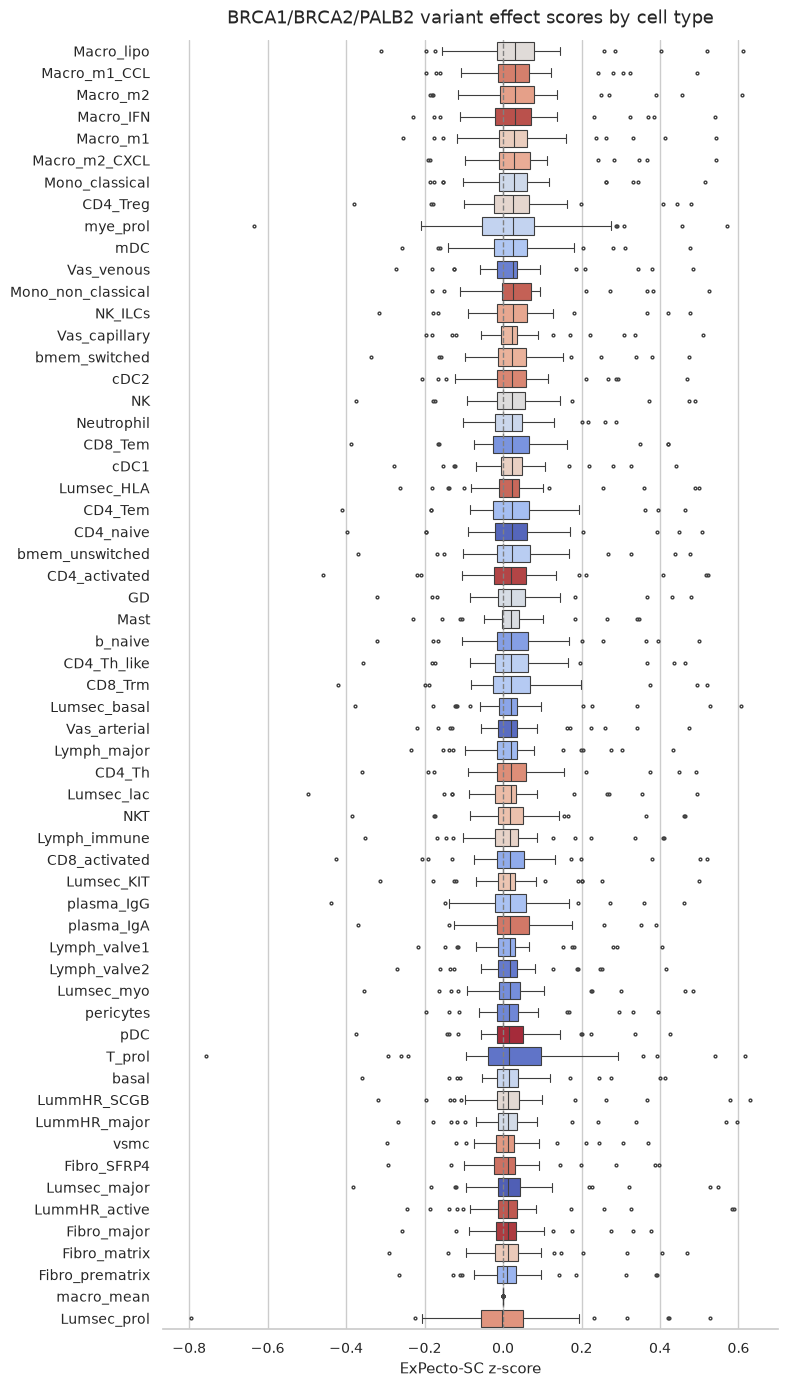

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=0.9)

# Order cell types by median z-score so the plot reads top-to-bottom meaningfully
order = (
    df_brca_long.groupby('cell_type')['zscore']
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(8, 14))

sns.boxplot(
    x='zscore',
    y='cell_type',
    data=df_brca_long,
    order=order,
    hue='cell_type',
    palette='coolwarm',
    legend=False,
    fliersize=2,
    linewidth=0.8,
    ax=ax,
)

ax.axvline(0, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('ExPecto-SC z-score', fontsize=11)
ax.set_ylabel('')
ax.set_title('BRCA1/BRCA2/PALB2 variant effect scores by cell type', fontsize=13, pad=12)
sns.despine(left=True)

plt.tight_layout()
plt.show()

In [8]:
df_brca.to_csv("merged_brca_expecto.csv")

/storage/scratch/tmp/ipykernel_2748195/156398460.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(labels)


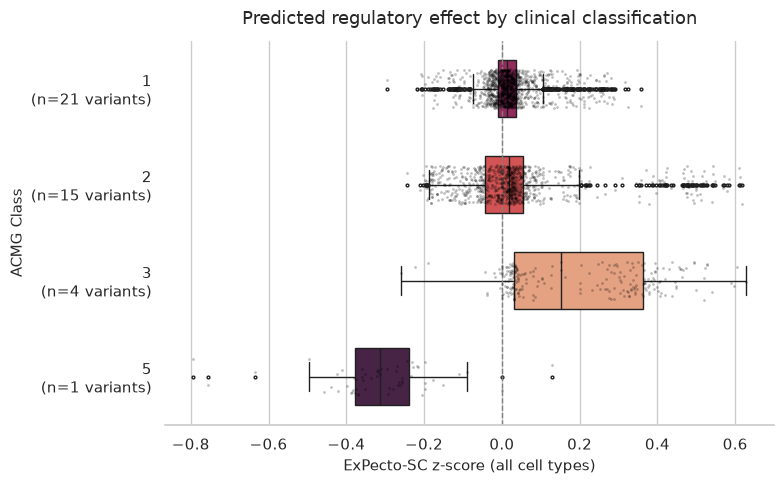

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=1.0)

# Keep Class as a category, ordered numerically (not alphabetically)
class_order = sorted(df_brca_long['Class'].unique())

# Show how many variants (not rows) back each box — important given the small/uneven n per class
n_variants = df_brca_long.groupby('Class')['SNP'].nunique()
labels = [f"{c}\n(n={n_variants[c]} variants)" for c in class_order]

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    x='zscore',
    y='Class',
    data=df_brca_long,
    order=class_order,
    hue='Class',
    palette='rocket_r',
    legend=False,
    fliersize=2,
    linewidth=1,
    width=0.6,
    ax=ax,
)

# Overlay individual points so the small-n classes (esp. Class 5, n=1 variant) aren't just an empty-looking box
sns.stripplot(
    x='zscore',
    y='Class',
    data=df_brca_long,
    order=class_order,
    color='black',
    size=2,
    alpha=0.25,
    jitter=0.2,
    ax=ax,
)

ax.axvline(0, color='grey', linestyle='--', linewidth=1)
ax.set_yticklabels(labels)
ax.set_xlabel('ExPecto-SC z-score (all cell types)', fontsize=11)
ax.set_ylabel('ACMG Class', fontsize=11)
ax.set_title('Predicted regulatory effect by clinical classification', fontsize=13, pad=12)
sns.despine(left=True)

plt.tight_layout()
plt.show()

In [ ]:
# clinvar has a tab with class downloadable, filter for variants